# AI-Generated Text Detection — EDA
Competition: [ai-generated-text-detection-hw3-ucu-ai-2026](https://www.kaggle.com/competitions/ai-generated-text-detection-hw3-ucu-ai-2026)

**Data**: `train.csv` — `id, text, lang, domain, label`; `test.csv` (25,000 rows) — same without `label`.
- `lang`: `en-EN`, `de-DE`
- `domain`: news, arXiv papers, blogs, UK / German parliament, court cases, student essays, books
- `label`: `human`, `ai`, `fusion` (part human, part AI)

## 0. Hypotheses: what should separate the classes?

**human**
- **Burstiness**: sentence lengths vary a lot; AI text is more uniform.
- **Messiness**: typos, odd capitalization, lowercase `i` (EN), repeated chars (`sooo`, `!!!`), double spaces, missing final punctuation, abrupt endings.
- **Informal markers** (blogs, essays): emojis, emoticons, slang, contractions, rhetorical `?`/`!`.
- **Domain artefacts**: parliament transcripts (`(Beifall)`, `Hon. Members`, speaker names), court-case citations, arXiv LaTeX remnants (`$...$`, `\cite`), news datelines. Generators rarely reproduce these.
- More rare words and hapax legomena.

**ai**
- **Uniform, polished style**: even sentence lengths, correct casing, every sentence ends with punctuation.
- **Typographic tells**: em dash `—`, curly quotes `“ ”` (EN), the `…` character, markdown (`**bold**`, bullets, `###`).
- **Stock phrases**: EN *delve, moreover, furthermore, crucial, it is important to note, in conclusion, plays a crucial role*; DE *darüber hinaus, zudem, insgesamt, zusammenfassend, es ist wichtig zu beachten, spielt eine entscheidende Rolle*.
- Summarising endings, hedging, balanced paragraphs.

**fusion**: averages over the whole text blur the two styles, so look for **within-text inconsistency**:
- A **style shift point**: first and second halves differ in sentence length, word length, punctuation, casing, typography.
- Higher **variance of per-sentence features** than either pure class.
- Domain artefacts or typos only in **part** of the text.

**Confounders**: German capitalizes every noun (so `upper_ratio` is higher) and uses `„ “` quotes; domains differ a lot in style (court cases vs blogs). So compare classes **within** each `lang` and `domain`, not only globally, and check that train and test have the same lang/domain mix.

Emojis (§6) and capitalization (§7) get their own sections.

## 1. Setup

In [1]:
# !pip install -q -r requirements.txt
import re, string, zipfile, subprocess
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

In [2]:
COMP = "ai-generated-text-detection-hw3-ucu-ai-2026"
DATA_DIR = Path("data")
KAGGLE_INPUT = Path("/kaggle/input") / COMP   # used automatically when running on Kaggle

TEXT, LANG, DOMAIN, LABEL = "text", "lang", "domain", "label"
CLASSES = ["human", "ai", "fusion"]
LANGS = ["en-EN", "de-DE"]
RANDOM_STATE = 42
BASELINE_N = 30_000   # rows used for the n-gram and baseline sections (speed)

## 2. Download data
Needs a Kaggle API token: `~/.kaggle/kaggle.json`, `KAGGLE_USERNAME` + `KAGGLE_KEY`, or `KAGGLE_API_TOKEN`. Accept the competition rules on the website first, or the download returns 403.

In [4]:
if KAGGLE_INPUT.exists():
    DATA_DIR = KAGGLE_INPUT
elif not (DATA_DIR / "train.csv").exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.run(["kaggle", "competitions", "download", "-c", COMP, "-p", str(DATA_DIR)], check=True)
    for z in DATA_DIR.glob("*.zip"):
        with zipfile.ZipFile(z) as zf:
            zf.extractall(DATA_DIR)

for p in sorted(DATA_DIR.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(DATA_DIR)}  ({p.stat().st_size / 1e6:.1f} MB)")

ai-generated-text-detection-hw3-ucu-ai-2026.zip  (398.1 MB)
sample_submission.csv  (0.3 MB)
test.csv  (83.4 MB)
train.csv  (954.8 MB)


## 3. Load & validate schema

In [5]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sub_path = next(iter(sorted(DATA_DIR.glob("sample_submission*.csv"))), None)
sample_sub = pd.read_csv(sub_path) if sub_path else None

assert {"id", TEXT, LANG, DOMAIN, LABEL} <= set(train.columns), train.columns.tolist()
assert {"id", TEXT, LANG, DOMAIN} <= set(test.columns) and LABEL not in test.columns, test.columns.tolist()
print(f"train: {train.shape} | test: {test.shape} (expected 25,000 rows)")

for df in (train, test):
    df[TEXT] = df[TEXT].fillna("").astype(str)

# Unexpected category values?
print("labels:", sorted(train[LABEL].unique()), "| unexpected:", set(train[LABEL]) - set(CLASSES))
print("langs:", sorted(set(train[LANG]) | set(test[LANG])), "| unexpected:", (set(train[LANG]) | set(test[LANG])) - set(LANGS))
DOMAINS = train[DOMAIN].value_counts().index.tolist()
print("domains (train):", DOMAINS)
print("domains only in test:", set(test[DOMAIN]) - set(DOMAINS))
print("id unique:", train["id"].is_unique, test["id"].is_unique, "| train/test id overlap:", len(set(train["id"]) & set(test["id"])))

display(train.head())
if sample_sub is not None:
    print("sample submission:"); display(sample_sub.head())

train: (272352, 5) | test: (25000, 4) (expected 25,000 rows)
labels: ['ai', 'fusion', 'human'] | unexpected: set()
langs: ['de-DE', 'en-EN'] | unexpected: set()
domains (train): ['student_essays', 'bundestag', 'cnn_news', 'blog_authorship_corpus', 'house_of_commons', 'euro_court_cases', 'arxiv_papers', 'gutenberg']
domains only in test: set()
id unique: True True | train/test id overlap: 0


,id,text,lang,domain,label
0,e7adad,Diego's Demons Return: Is the Football Legend Losing Control? Fans have been left heartbroken and bewildered as whispers swirl about Diego Maradona's health and personal life taking a dramatic tur...,en-EN,cnn_news,ai
1,3bab63,"Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern, wenn ich nach drei Jahren Regierungszeit, nachdem drei Viertel dieser Regierungszeit vergangen sind, positive Bilanz zi...",de-DE,bundestag,human
2,4e6c1f,"Frau Präsidentin! Liebe Kolleginnen und Kollegen! Dem Kollegen Kühn stimme ich in Bezug auf das, was er am Anfang gesagt hat, zu. Wir haben in der Tat eine extrem schwere Krise. Eigentlich ist es ...",de-DE,bundestag,human
3,f92d07,[12/17/2002 9:40:16 PM | + racheal] shagging. I feel sick. I want to go throw up and throw up and throw up. I dont know what it isremnants of dinner flushed down with red wine and biscotti feels t...,en-EN,blog_authorship_corpus,human
4,6162f5,"IN THE COURT OF CASE NO. , Plaintiffs, v. , Defendant. RULING ON PENSION CLAIMS I. INTRODUCTION 1. This matter comes before the Court on the claims of the Plaintiffs, , seeking pension benefits ar...",en-EN,euro_court_cases,ai


sample submission:


,id,label
0,8ff2d1,ai
1,a261cf,ai
2,ad5614,ai
3,3a23ac,ai
4,28b4e5,ai


## 4. Overview: label balance by lang & domain, train/test shift, duplicates

nulls:
         train  test
id          0   0.0
text        0   0.0
lang        0   0.0
domain      0   0.0
label       0   NaN 



,count,share
label,,
human,66730,0.245
ai,121940,0.448
fusion,83682,0.307


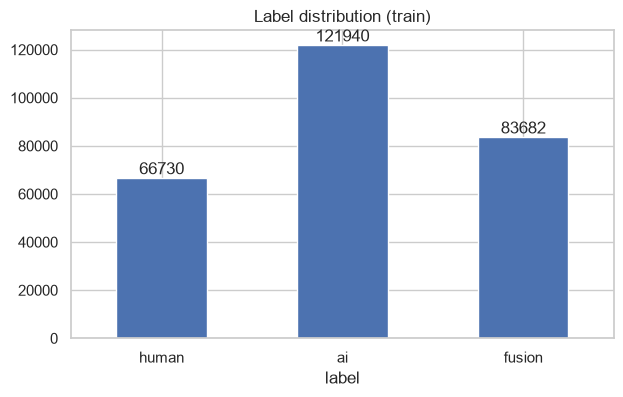

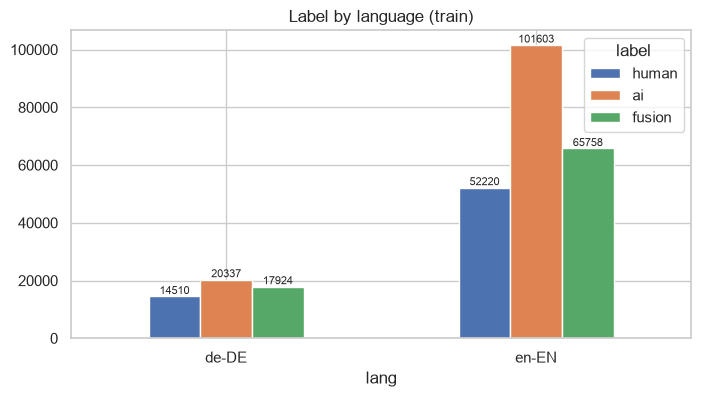

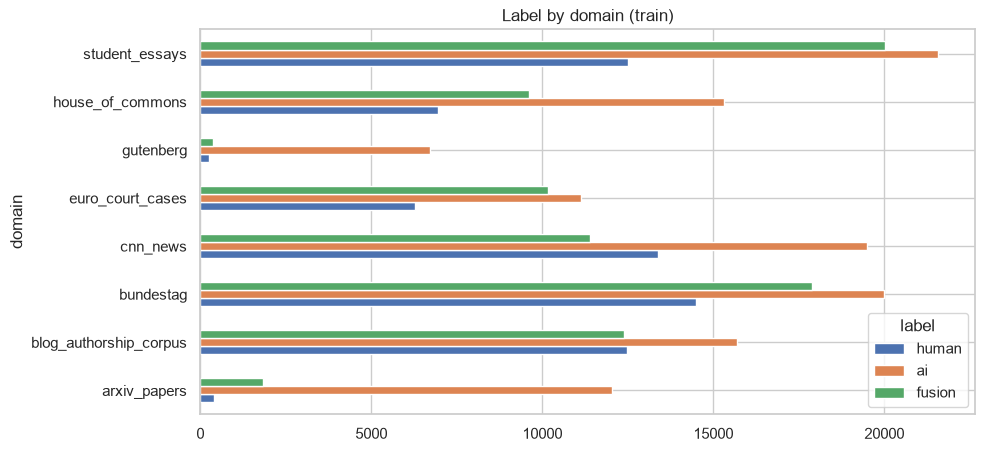

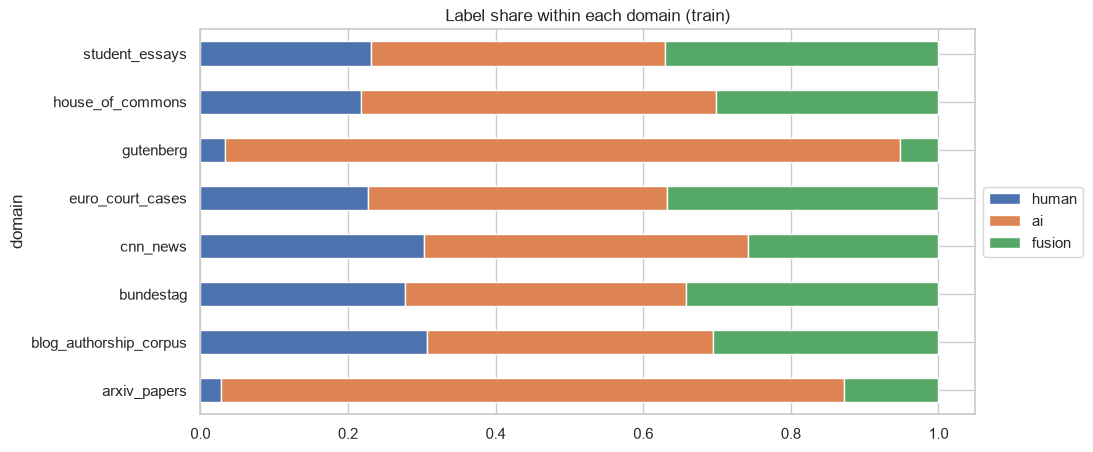

Label share within each lang × domain (rows sum to 1):


label                         human     ai  fusion      n
lang  domain                                             
de-DE bundestag               0.277  0.382   0.342  52343
      gutenberg               0.072  0.841   0.086    428
en-EN arxiv_papers            0.028  0.843   0.128  14290
      blog_authorship_corpus  0.307  0.387   0.306  40547
      cnn_news                0.302  0.440   0.257  44285
      euro_court_cases        0.228  0.404   0.368  27578
      gutenberg               0.031  0.919   0.049   6916
      house_of_commons        0.218  0.480   0.302  31859
      student_essays          0.231  0.399   0.370  54106

In [6]:
print("nulls:\n", pd.concat({"train": train.isna().sum(), "test": test.isna().sum()}, axis=1), "\n")

counts = train[LABEL].value_counts().reindex(CLASSES)
display(pd.DataFrame({"count": counts, "share": (counts / len(train)).round(3)}))

ax = counts.plot.bar(figsize=(7, 4), rot=0, title="Label distribution (train)")
ax.bar_label(ax.containers[0])
plt.show()

ax = pd.crosstab(train[LANG], train[LABEL])[CLASSES].plot.bar(figsize=(8, 4), rot=0, title="Label by language (train)")
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
plt.show()

ax = pd.crosstab(train[DOMAIN], train[LABEL])[CLASSES].plot.barh(figsize=(10, 5), title="Label by domain (train)")
plt.show()

ax = pd.crosstab(train[DOMAIN], train[LABEL], normalize="index")[CLASSES].plot.barh(
    stacked=True, figsize=(10, 5), title="Label share within each domain (train)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

print("Label share within each lang × domain (rows sum to 1):")
display(pd.crosstab([train[LANG], train[DOMAIN]], train[LABEL], normalize="index")[CLASSES].round(3)
        .assign(n=train.groupby([LANG, DOMAIN]).size()))

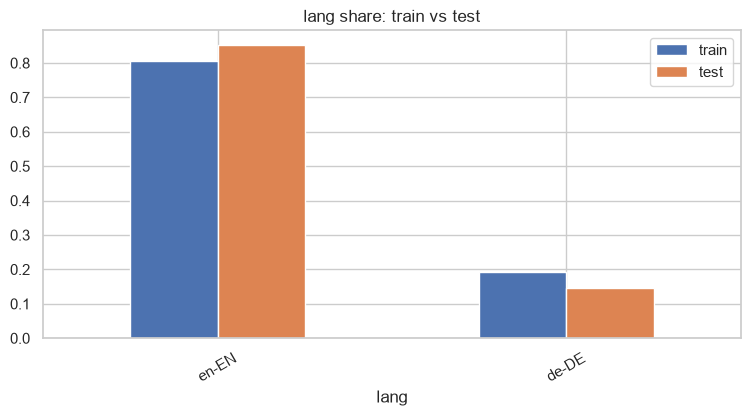

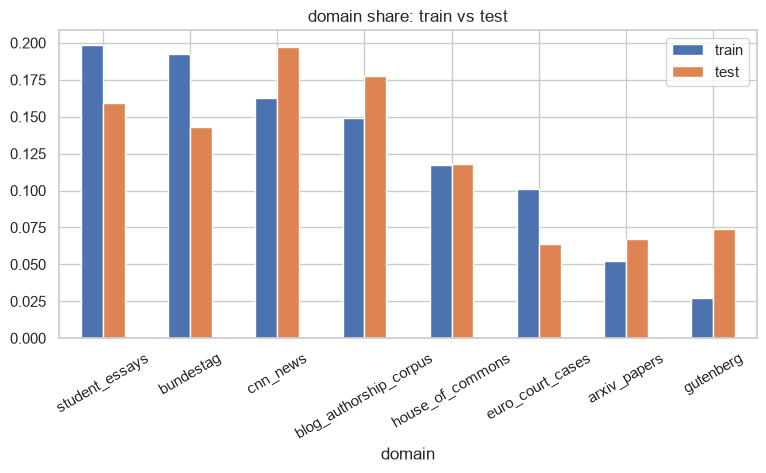

In [6]:
# Train vs test: same lang / domain mix?
mix = pd.concat({
    "train": train.groupby([LANG, DOMAIN]).size() / len(train),
    "test": test.groupby([LANG, DOMAIN]).size() / len(test),
}, axis=1).fillna(0).round(4)
mix["diff"] = (mix["test"] - mix["train"]).round(4)
display(mix.style.background_gradient(subset=["diff"], cmap="coolwarm"))

for col in [LANG, DOMAIN]:
    pd.concat({"train": train[col].value_counts(normalize=True),
               "test": test[col].value_counts(normalize=True)}, axis=1).plot.bar(
        figsize=(9, 4), rot=30, title=f"{col} share: train vs test")
    plt.show()

## 5. Stylometric features (per language)

In [6]:
WORD_RE = re.compile(r"\w+", re.UNICODE)
SENT_SPLIT = re.compile(r"(?<=[.!?…])\s+|\n+")
MD_RE = re.compile(r"^\s*(#{1,6}\s|[-*•]\s|\d+[.)]\s)", re.M)
LATEX_RE = re.compile(r"\$[^$]+\$|\\(cite|ref|begin|end|frac|mathbf|emph)\b")

def split_sents(t):
    return [s for s in SENT_SPLIT.split(t.strip()) if WORD_RE.search(s)]

def text_features(t):
    words = WORD_RE.findall(t)
    nw, nc = max(len(words), 1), max(len(t), 1)
    sents = split_sents(t)
    sl = np.array([len(WORD_RE.findall(s)) for s in sents]) if sents else np.array([0])
    letters = [c for c in t if c.isalpha()]
    nl = max(len(letters), 1)
    freq = Counter(w.lower() for w in words)
    stripped = t.rstrip()
    return {
        "n_chars": len(t),
        "n_words": len(words),
        "n_sents": len(sents),
        "n_paragraphs": len([p for p in re.split(r"\n\s*\n", t.strip()) if p.strip()]),
        "avg_word_len": np.mean([len(w) for w in words]) if words else 0,
        "avg_sent_len": sl.mean(),
        "std_sent_len": sl.std(),
        "burstiness": sl.std() / (sl.mean() + 1e-9),
        "ttr": len(freq) / nw,
        "hapax_ratio": sum(v == 1 for v in freq.values()) / nw,
        "upper_ratio": sum(c.isupper() for c in letters) / nl,
        "digit_ratio": sum(c.isdigit() for c in t) / nc,
        "punct_ratio": sum(c in string.punctuation for c in t) / nc,
        "comma_per_word": t.count(",") / nw,
        "excl_per_sent": t.count("!") / max(len(sents), 1),
        "quest_per_sent": t.count("?") / max(len(sents), 1),
        "paren_per_word": t.count("(") / nw,
        "semicolon_colon": t.count(";") + t.count(":"),
        "newlines": t.count("\n"),
        "double_space": t.count("  "),
        "em_dash": t.count("—"),
        "en_dash": t.count("–"),
        "curly_quotes_en": sum(t.count(c) for c in "“”‘’"),
        "quotes_de": sum(t.count(c) for c in "„‚«»"),
        "ascii_quotes": t.count('"') + t.count("'"),
        "ellipsis_char": t.count("…"),
        "three_dots": t.count("..."),
        "markdown": len(MD_RE.findall(t)) + t.count("**"),
        "latex": len(LATEX_RE.findall(t)),
        "repeated_chars": len(re.findall(r"(.)\1{2,}", t)),
        "umlaut_ratio": sum(c in "äöüÄÖÜß" for c in t) / nl,
        "non_ascii_ratio": sum(ord(c) > 127 for c in t) / nc,
        "ends_with_punct": int(bool(stripped) and stripped[-1] in ".!?…\"'”“»)"),
        "starts_upper": int(bool(letters) and letters[0].isupper()),
    }

feats = pd.DataFrame([text_features(t) for t in train[TEXT]], index=train.index)
FEATS = feats.columns.tolist()
feats[[LABEL, LANG, DOMAIN]] = train[[LABEL, LANG, DOMAIN]]

print("Median feature value per lang × label:")
display(feats.groupby([LANG, LABEL])[FEATS].median().T.style.background_gradient(axis=1, cmap="coolwarm"))

Median feature value per lang × label:


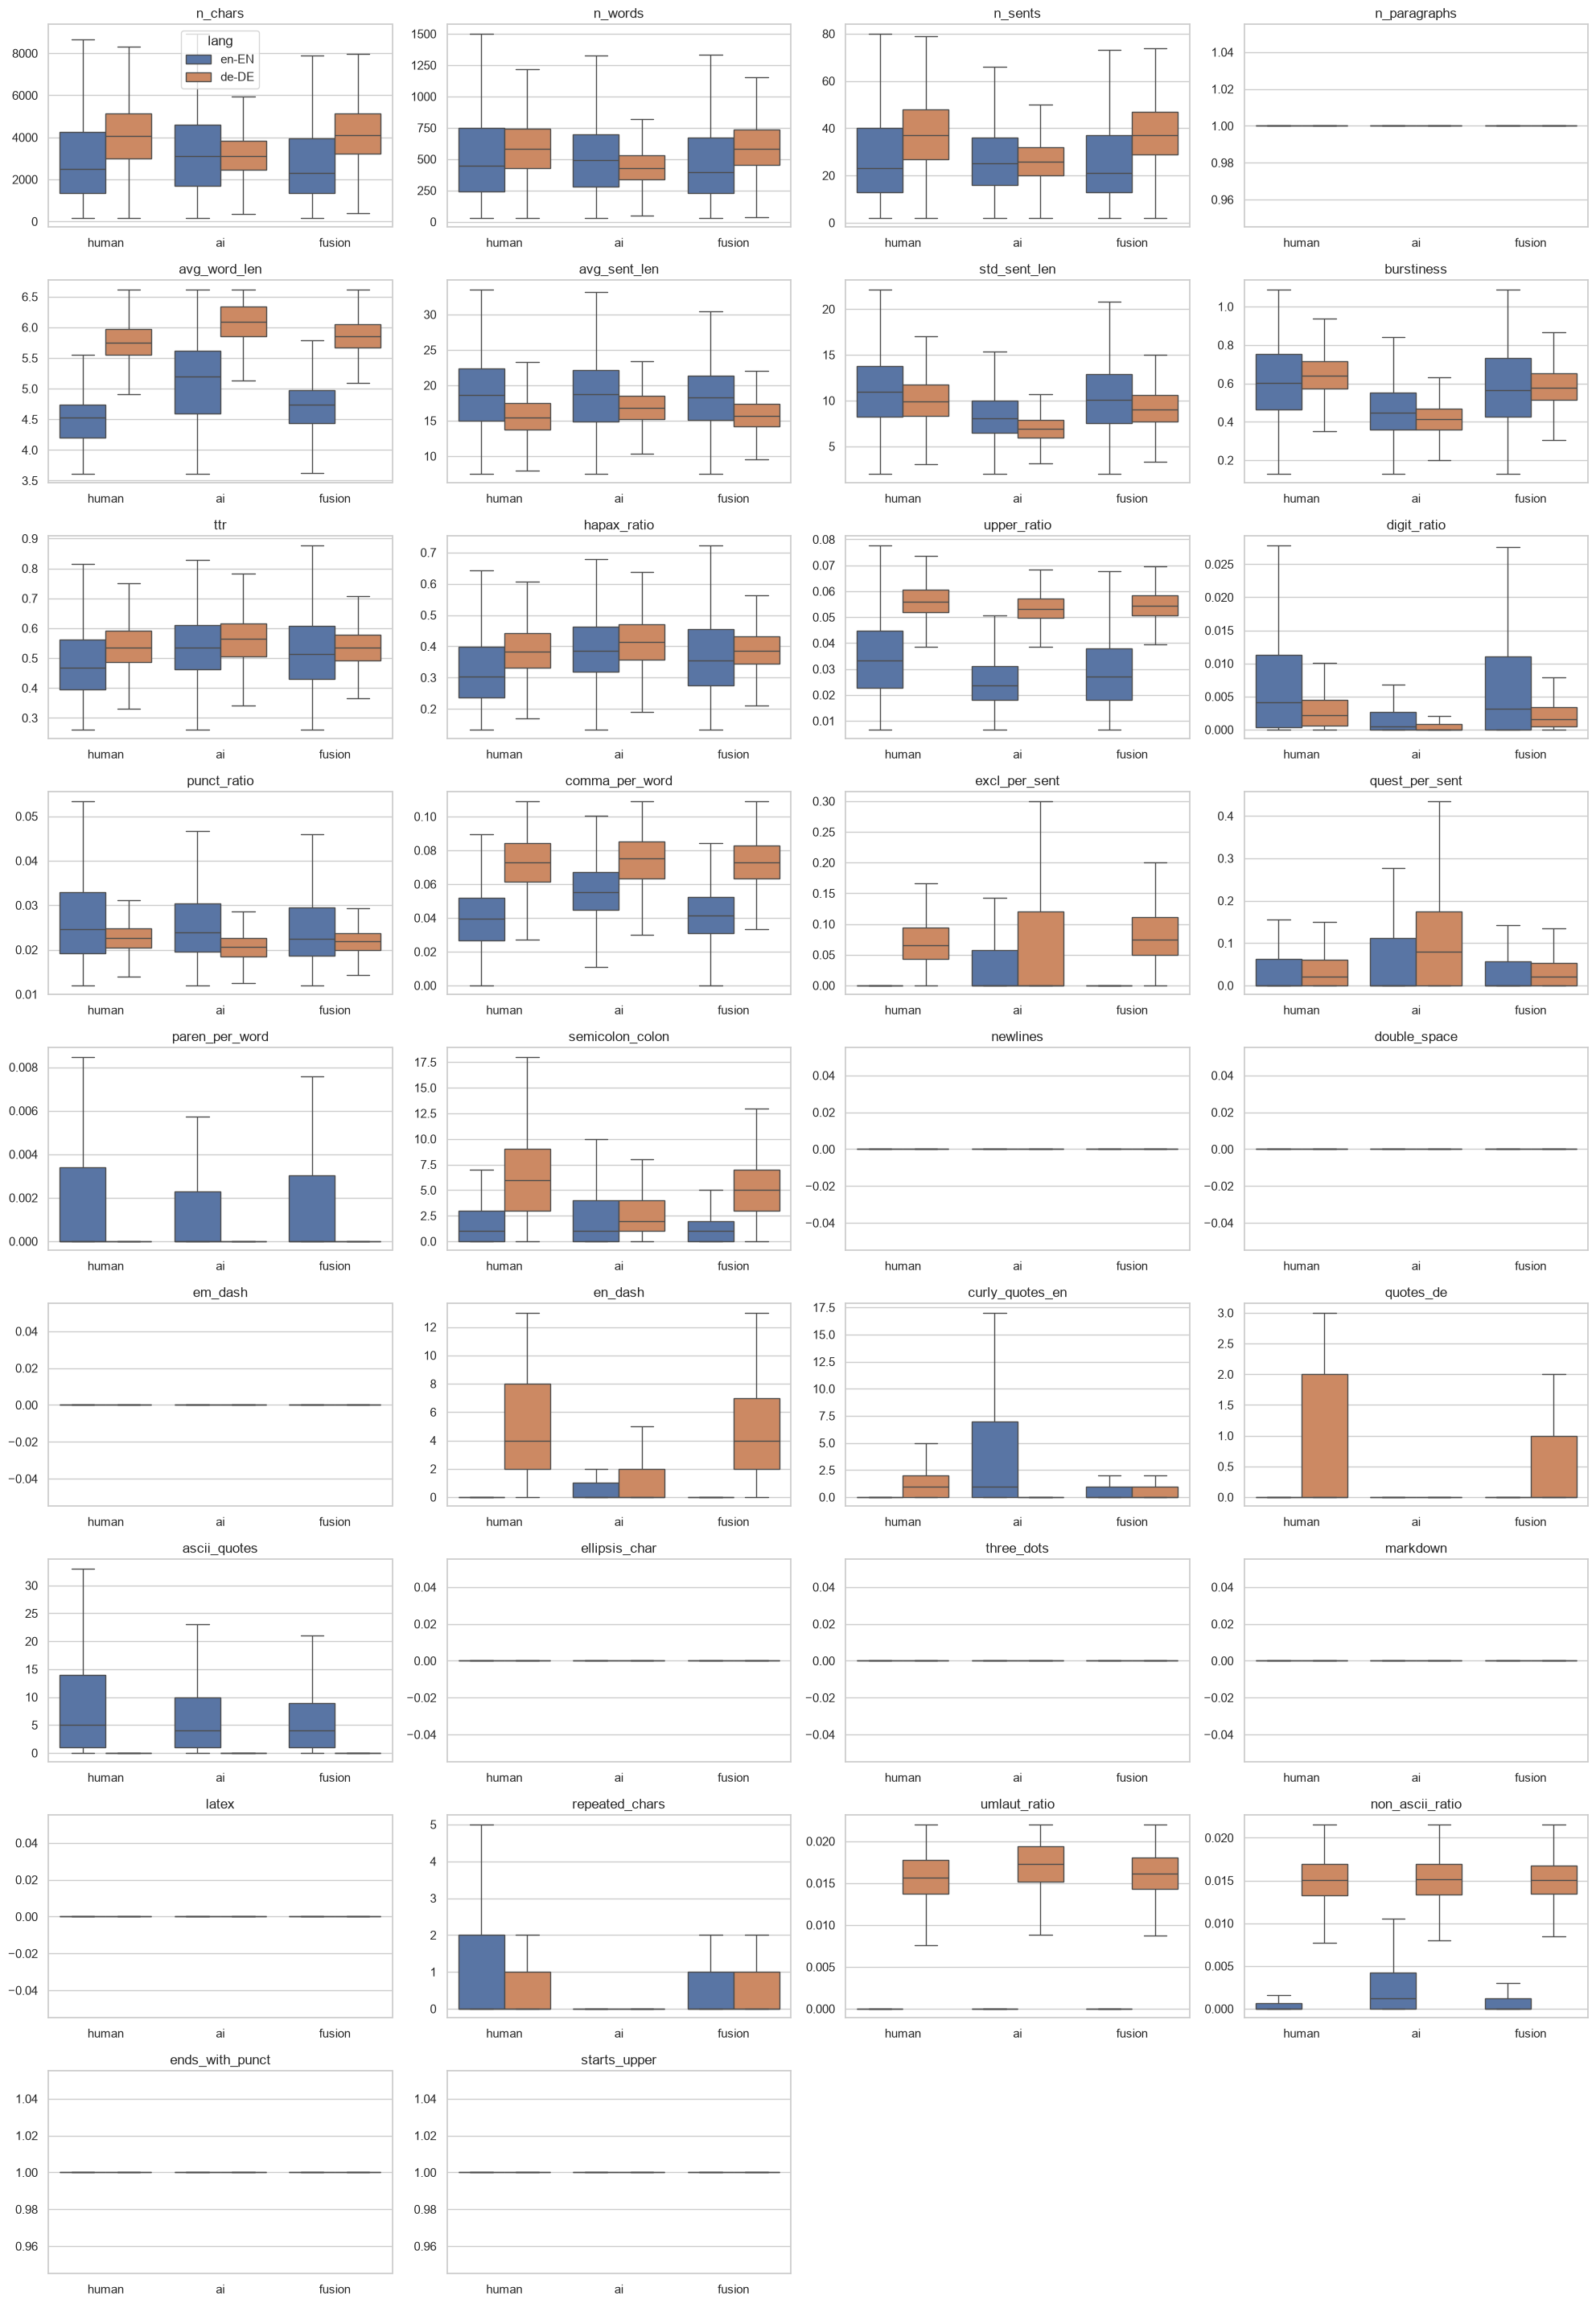

In [7]:
# Distributions per label, split by language (clipped at 1st/99th percentile)
ncols = 4
nrows = int(np.ceil(len(FEATS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.2 * nrows))
for i, (ax, f) in enumerate(zip(axes.flat, FEATS)):
    lo, hi = feats[f].quantile([0.01, 0.99])
    sns.boxplot(data=feats.assign(**{f: feats[f].clip(lo, hi)}), x=LABEL, y=f, hue=LANG,
                order=CLASSES, hue_order=LANGS, ax=ax, showfliers=False, legend=(i == 0))
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[len(FEATS):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

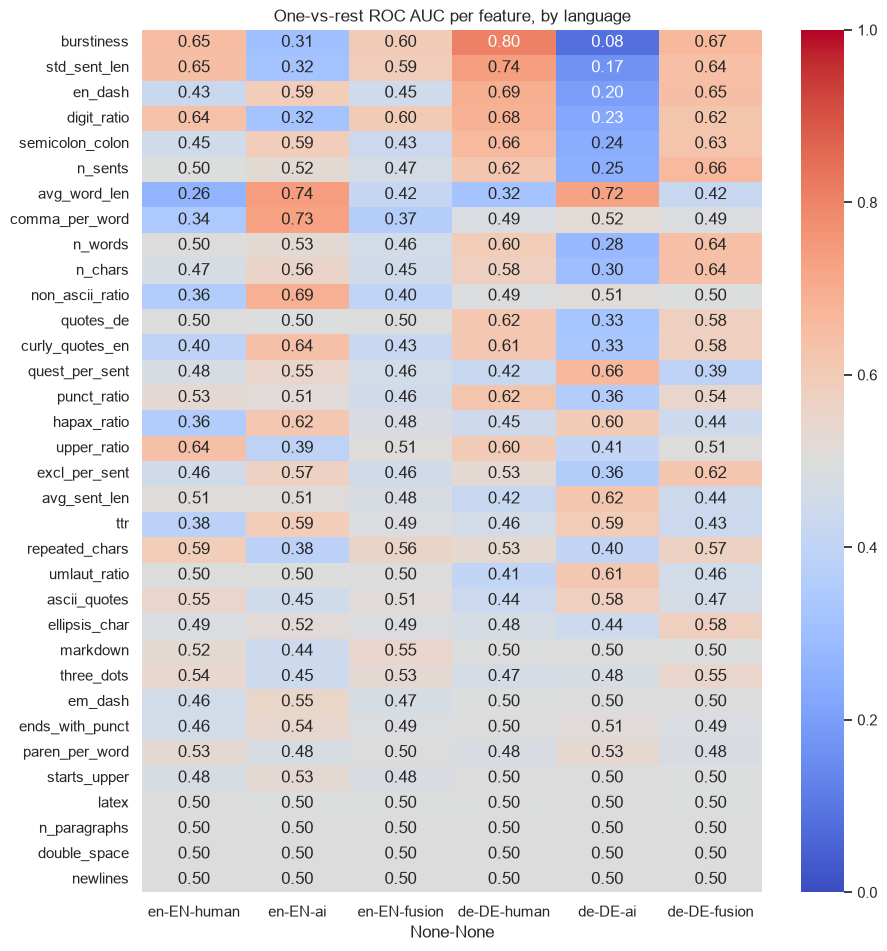

In [8]:
# One-vs-rest ROC AUC per feature, computed within each language (0.5 = useless; far from 0.5 either way = useful)
def auc_table(df, feat_cols):
    return pd.DataFrame({
        cls: {f: roc_auc_score(df[LABEL] == cls, df[f]) if df[f].nunique() > 1 and (df[LABEL] == cls).any()
              and not (df[LABEL] == cls).all() else 0.5 for f in feat_cols}
        for cls in CLASSES
    })

auc = pd.concat({lang: auc_table(feats[feats[LANG] == lang], FEATS) for lang in LANGS}, axis=1)
auc = auc.loc[(auc - 0.5).abs().max(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(10, 0.3 * len(FEATS) + 1))
sns.heatmap(auc, annot=True, fmt=".2f", cmap="coolwarm", center=0.5, vmin=0, vmax=1)
plt.title("One-vs-rest ROC AUC per feature, by language"); plt.show()

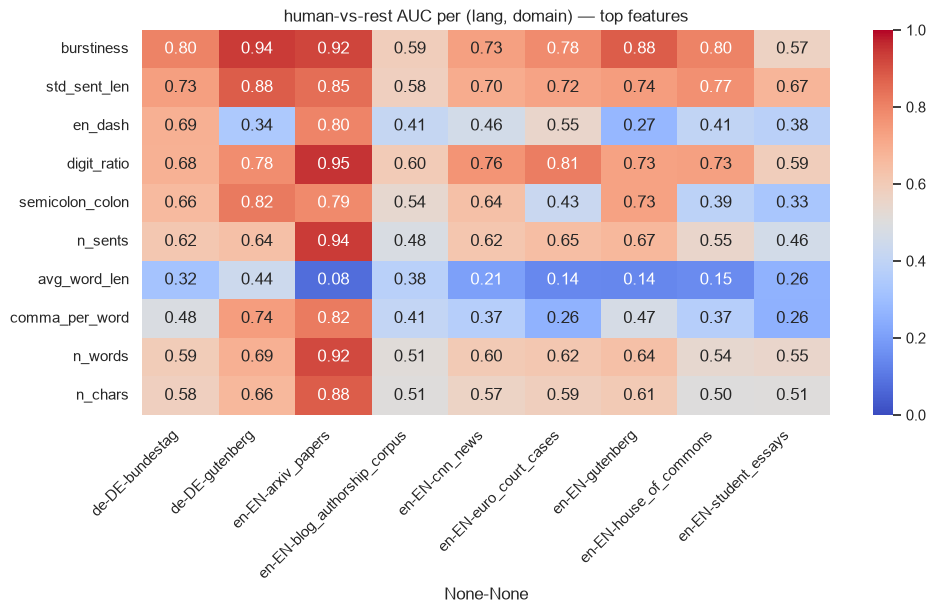

In [9]:
# Is a feature's signal stable across domains? (AUC of human-vs-rest per domain for the top features)
top_feats = auc.index[:10].tolist()
per_dom = pd.DataFrame({
    (lang, dom): auc_table(g, top_feats)["human"]
    for (lang, dom), g in feats.groupby([LANG, DOMAIN]) if g[LABEL].nunique() > 1
})
plt.figure(figsize=(0.9 * per_dom.shape[1] + 3, 5))
sns.heatmap(per_dom, annot=True, fmt=".2f", cmap="coolwarm", center=0.5, vmin=0, vmax=1)
plt.title("human-vs-rest AUC per (lang, domain) — top features"); plt.xticks(rotation=45, ha="right"); plt.show()

## 6. Emoji check
Unicode emoji ranges + text emoticons (`:)`, `:D`, `<3`, `xD`…). Expected mostly in blogs / student essays. Check per label, per domain and in test.

In [10]:
EMOJI_RE = re.compile(
    "["
    "\U0001F1E6-\U0001F1FF"  # flags
    "\U0001F300-\U0001F5FF"  # symbols & pictographs
    "\U0001F600-\U0001F64F"  # emoticons
    "\U0001F680-\U0001F6FF"  # transport & map
    "\U0001F700-\U0001F7FF"
    "\U0001F800-\U0001F8FF"
    "\U0001F900-\U0001F9FF"  # supplemental symbols
    "\U0001FA00-\U0001FAFF"  # extended-A
    "☀-⛿"          # misc symbols (☀ ☺ ♥ ...)
    "✀-➿"          # dingbats (✅ ✨ ❤ ...)
    "⬀-⯿"          # arrows/stars (⭐ ...)
    "]"
)
EMOTICON_RE = re.compile(r"(?<![\w:])(?:[:;=][\-^']?[)(\]\[DPpOo3/\\|*]|<3|\^_?\^|[xX]D|T_T|-_-)(?!\w)")

def emoji_stats(df):
    s = df[TEXT]
    out = pd.DataFrame({"n_emoji": s.str.count(EMOJI_RE), "n_emoticon": s.str.count(EMOTICON_RE)}, index=df.index)
    out["has_emoji"] = out["n_emoji"] > 0
    out["has_emoticon"] = out["n_emoticon"] > 0
    return out.join(df[[c for c in (LABEL, LANG, DOMAIN) if c in df]])

em_train, em_test = emoji_stats(train), emoji_stats(test)

agg = dict(texts=("has_emoji", "size"),
           pct_emoji=("has_emoji", lambda x: 100 * x.mean()),
           mean_emoji_if_any=("n_emoji", lambda x: x[x > 0].mean()),
           pct_emoticon=("has_emoticon", lambda x: 100 * x.mean()))
print("By label:");          display(em_train.groupby(LABEL).agg(**agg).reindex(CLASSES).round(2))
print("By lang × label:");   display(em_train.groupby([LANG, LABEL]).agg(**agg).round(2))
print("% texts with emoji by domain × label:")
display((em_train.pivot_table(index=DOMAIN, columns=LABEL, values="has_emoji", aggfunc="mean") * 100)[CLASSES].round(2))
print("Train vs test, % texts with emoji by domain:")
display(pd.concat({"train": em_train.groupby(DOMAIN)["has_emoji"].mean() * 100,
                   "test": em_test.groupby(DOMAIN)["has_emoji"].mean() * 100}, axis=1).round(2))

By label:


,texts,pct_emoji,mean_emoji_if_any,pct_emoticon
label,,,,
human,66730,0.03,38.89,1.65
ai,121940,2.69,5.99,0.26
fusion,83682,0.21,8.88,0.91


By lang × label:


texts  pct_emoji  mean_emoji_if_any  pct_emoticon
lang  label                                                     
de-DE ai       20337       0.01               5.00          0.00
      fusion   17924       0.00                NaN          0.00
      human    14510       0.00                NaN          0.00
en-EN ai      101603       3.23               5.99          0.31
      fusion   65758       0.27               8.88          1.16
      human    52220       0.04              38.89          2.11

% texts with emoji by domain × label:


label,human,ai,fusion
domain,,,
arxiv_papers,2.95,0.13,2.35
blog_authorship_corpus,0.03,20.05,0.94
bundestag,0.00,0.01,0.00
cnn_news,0.01,0.22,0.03
euro_court_cases,0.00,0.00,0.00
gutenberg,0.81,0.09,0.53
house_of_commons,0.00,0.00,0.10
student_essays,0.00,0.34,0.01


Train vs test, % texts with emoji by domain:


,train,test
domain,,
arxiv_papers,0.50,0.30
blog_authorship_corpus,8.05,8.52
bundestag,0.00,0.00
cnn_news,0.10,0.10
euro_court_cases,0.00,0.00
gutenberg,0.14,0.00
house_of_commons,0.03,0.00
student_essays,0.14,0.30


,human,ai,fusion
0,❄ ×284,😩 ×1436,❄ ×569
1,✔ ×45,😂 ×1396,✓ ×127
2,✯ ×42,😅 ×788,😊 ×118
3,❅ ×39,🙄 ×718,✔ ×90
4,✟ ×30,😭 ×717,✯ ×84
5,★ ×24,🤩 ×710,✟ ×54
6,✬ ×23,✨ ×542,✬ ×46
7,✼ ×20,🔥 ×528,✼ ×40
8,❲ ×20,🎉 ×495,❲ ×40
9,✶ ×15,♀ ×456,❅ ×30


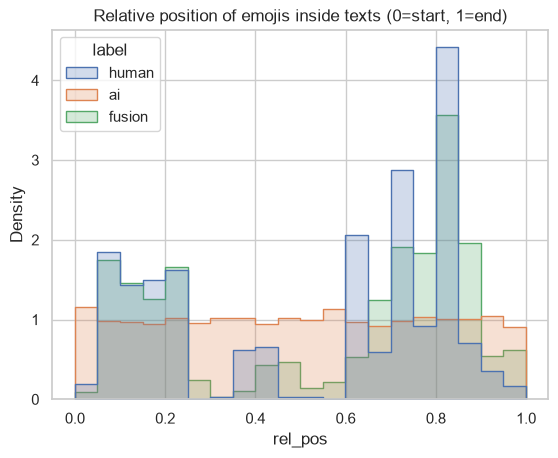


--- human: 19 texts with emoji
   [en-EN|arxiv_papers] 'Frame dependence of transition form factors in light-front dynamics Meijian Li∗ Iowa State University E-mail: meijianl@iastate.edu We study the radiative transitions between vector and pseudoscalar quarkonia in the light-front Hamiltonian approach, and investigate the effects of using different curr'
   [en-EN|arxiv_papers] 'arXiv:2001.00992v1 [math.CO] 3 Jan 2020 The Matching Number and Hamiltonicity of Graphs Rao Li Dept. of mathematical sciences University of South Carolina Aiken Aiken, SC 29801 Email: raol@usca.edu Feb. 25, 2017 Abstract The matching number of a graph G is the size of a maximum matching in the graph'
   [en-EN|gutenberg] 'Classical Enigmas, Adapted to Every Month in the Year: Composed from the English and Roman Histories, Heathen Mythology and Names of Famous Writers: Meant to Amuse Youths of All Ages, and at the Same Time Exert Their Memories, by Calling to Mind What They Have Read at Different Times Minor p

In [11]:
# Most common emojis per label, position inside the text, examples
top = {cls: Counter(e for t in train.loc[train[LABEL] == cls, TEXT] for e in EMOJI_RE.findall(t)).most_common(15)
       for cls in CLASSES}
display(pd.DataFrame({cls: pd.Series([f"{e} ×{n}" for e, n in v], dtype=object) for cls, v in top.items()}))

pos = pd.DataFrame([(m.start() / max(len(t), 1), y) for t, y in train.loc[em_train["has_emoji"], [TEXT, LABEL]].values
                    for m in EMOJI_RE.finditer(t)], columns=["rel_pos", LABEL])
if len(pos):
    sns.histplot(data=pos, x="rel_pos", hue=LABEL, hue_order=CLASSES, bins=20, stat="density", common_norm=False, element="step")
    plt.title("Relative position of emojis inside texts (0=start, 1=end)"); plt.show()

for cls in CLASSES:
    ex = train.loc[(train[LABEL] == cls) & em_train["has_emoji"]]
    print(f"\n--- {cls}: {len(ex)} texts with emoji")
    for _, r in ex.head(3).iterrows():
        print(f"   [{r[LANG]}|{r[DOMAIN]}]", repr(r[TEXT][:300]))

## 7. Capitalization check
Some texts are **entirely UPPERCASE** or **entirely lowercase**. Questions:
1. Is that casing tied to the label (a real signal) or spread across all labels at random (augmentation/noise → normalise case or use case-insensitive features)?
2. Does it depend on language/domain? German capitalizes all nouns, so `upper_ratio` and "sentence starts lowercase" must be compared **within** a language.

In [12]:
def case_profile(t):
    cased = [c for c in t if c.isalpha() and (c.isupper() or c.islower())]
    n = len(cased)
    up = sum(c.isupper() for c in cased)
    if n == 0:
        case_class = "no_letters"
    elif up == n:
        case_class = "ALL_UPPER"
    elif up == 0:
        case_class = "all_lower"
    elif up / n > 0.8:
        case_class = "MOSTLY_UPPER"
    else:
        case_class = "normal"

    sents = split_sents(t)
    first_letters = [next((c for c in s if c.isalpha()), "") for s in sents]
    sent_upper = [s for s in sents if sum(c.isalpha() for c in s) >= 3 and not any(c.islower() for c in s)]
    sent_lower = [s for s in sents if sum(c.isalpha() for c in s) >= 3 and not any(c.isupper() for c in s)]
    ns = max(len(sents), 1)
    words = WORD_RE.findall(t)
    return {
        "case_class": case_class,
        "upper_ratio": up / max(n, 1),
        "sent_start_lower_frac": sum(c.islower() for c in first_letters) / ns,
        "sent_all_upper_frac": len(sent_upper) / ns,
        "sent_all_lower_frac": len(sent_lower) / ns,
        # some sentences fully upper/lower while others are normal -> casing changes within the text
        "case_inconsistent": int(0 < len(sent_upper) + len(sent_lower) < len(sents)),
        "lowercase_i": len(re.findall(r"(?<!\w)i(?!\w)", t)),   # EN only: "i" pronoun written lowercase
        "shout_words": sum(len(w) >= 3 and w.isupper() for w in words),
        "title_word_frac": sum(w[:1].isupper() and w[1:].islower() for w in words) / max(len(words), 1),
    }

cp = pd.DataFrame([case_profile(t) for t in train[TEXT]], index=train.index)
cp[[LABEL, LANG, DOMAIN]] = train[[LABEL, LANG, DOMAIN]]
cp_test = pd.DataFrame([case_profile(t) for t in test[TEXT]], index=test.index)
cp_test[[LANG, DOMAIN]] = test[[LANG, DOMAIN]]

print("Case class × label — counts:")
display(pd.crosstab(cp["case_class"], cp[LABEL], margins=True))
print("Label distribution within each case class (rows sum to 1) — compare with overall label shares:")
display(pd.crosstab(cp["case_class"], cp[LABEL], normalize="index")[CLASSES].round(3))
print("Case class share by lang × label:")
display(pd.crosstab([cp[LANG], cp[LABEL]], cp["case_class"], normalize="index").round(3))
print("% of texts that are ALL_UPPER or all_lower, by domain — train vs test:")
odd = lambda d: d["case_class"].isin(["ALL_UPPER", "all_lower"])
display(pd.concat({"train": odd(cp).groupby(cp[DOMAIN]).mean() * 100,
                   "test": odd(cp_test).groupby(cp_test[DOMAIN]).mean() * 100}, axis=1).round(2))

Case class × label — counts:


label,ai,fusion,human,All
case_class,,,,
ALL_UPPER,6,4,14,24
MOSTLY_UPPER,7,6,16,29
all_lower,102,226,680,1008
normal,121825,83446,66020,271291
All,121940,83682,66730,272352


Label distribution within each case class (rows sum to 1) — compare with overall label shares:


label,human,ai,fusion
case_class,,,
ALL_UPPER,0.583,0.250,0.167
MOSTLY_UPPER,0.552,0.241,0.207
all_lower,0.675,0.101,0.224
normal,0.243,0.449,0.308


Case class share by lang × label:


case_class    ALL_UPPER  MOSTLY_UPPER  all_lower  normal
lang  label                                             
de-DE ai            0.0           0.0      0.000   1.000
      fusion        0.0           0.0      0.000   1.000
      human         0.0           0.0      0.000   1.000
en-EN ai            0.0           0.0      0.001   0.999
      fusion        0.0           0.0      0.003   0.996
      human         0.0           0.0      0.013   0.986

% of texts that are ALL_UPPER or all_lower, by domain — train vs test:


,train,test
domain,,
arxiv_papers,0.00,0.00
blog_authorship_corpus,2.34,2.54
bundestag,0.00,0.00
cnn_news,0.00,0.00
euro_court_cases,0.00,0.00
gutenberg,0.01,0.00
house_of_commons,0.00,0.00
student_essays,0.15,0.20


Sentence-level casing, normally-cased texts only, by lang × label:


upper_ratio  sent_start_lower_frac  sent_all_upper_frac  sent_all_lower_frac  case_inconsistent  lowercase_i  shout_words  title_word_frac
lang  label                                                                                                                                             
de-DE ai            0.053                  0.002                0.000                0.000              0.005        0.000        0.860            0.315
      fusion        0.055                  0.010                0.000                0.001              0.042        0.001        1.994            0.305
      human         0.056                  0.007                0.000                0.001              0.043        0.001        2.292            0.306
en-EN ai            0.027                  0.016                0.002                0.009              0.120        0.055        2.147            0.103
      fusion        0.031                  0.074                0.004                0.044              0.363        0.480        2.990            0.102
      human         0.037                  0.092                0.005                0.047              0.356        0.540        2.761            0.117

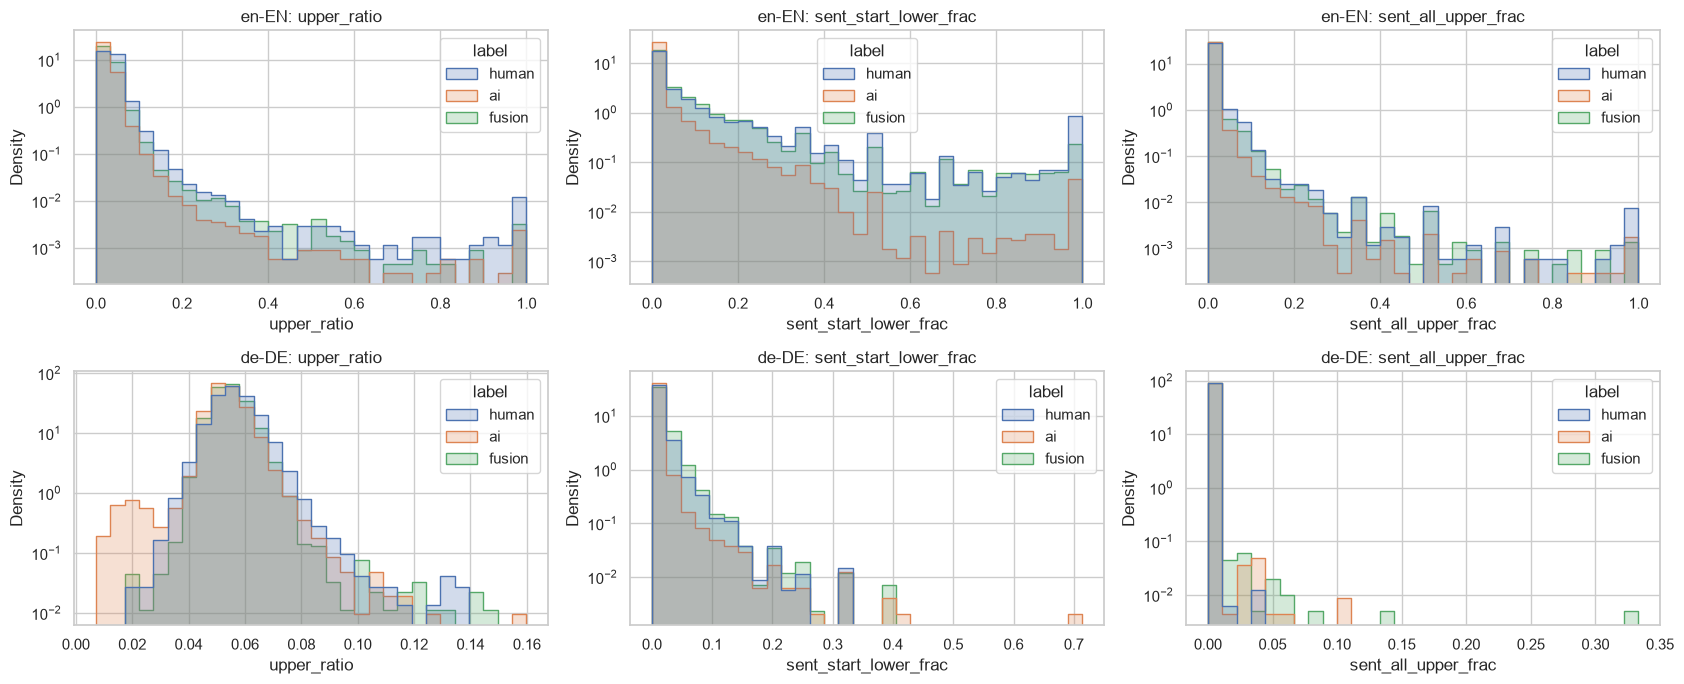

,n_chars,n_words,avg_sent_len
case_class,,,
ALL_UPPER,789.5,87.5,17.722222
MOSTLY_UPPER,754.0,119.0,15.974359
all_lower,548.5,108.0,13.000000
normal,2986.0,470.0,17.800000



--- ALL_UPPER: 24 texts
  [human|en-EN|student_essays] "TO THE FELLOW CITIZENS OUT THERE WE ARE LIMITING CAR'S BECAUES PEOPLE DONT LIKE TO PAY THERE CAR, BECAUES THEY EIGTHER DONT HAVE THE MONEY FOR IT OR THEY JUST DONT WANNA PAY IT.. PEOPLE ALL AROUND THE COUNTRY DONT LIEK AYING THER CADR THATS WHY PEOPL"
  [human|en-EN|blog_authorship_corpus] 'HEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEE EEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEE EEEEEEEEEEEEE'
  [fusion|en-EN|student_essays] "TO THE FELLOW CITIZENS OUT THERE WE ARE LIMITING CAR'S BECAUES PEOPLE DONT LIKE TO PAY THERE CAR, BECAUES THEY EIGTHER DONT HAVE THE MONEY FOR IT OR THEY JUST DONT WANNA PAY IT.. PEOPLE ALL AROUND THE COUNTRY DONT LIEK AYING THER CADR THATS WHY PEOPL"
  [human|en-EN|student_essays] 'THE ADVANTAGES IN LIMITING CAR USAGE ARE VERY DRASTIC. IN THIS NEW APPOROACH STORE

In [13]:
case_num = ["upper_ratio", "sent_start_lower_frac", "sent_all_upper_frac", "sent_all_lower_frac", "case_inconsistent",
            "lowercase_i", "shout_words", "title_word_frac"]
print("Sentence-level casing, normally-cased texts only, by lang × label:")
display(cp[cp["case_class"] == "normal"].groupby([LANG, LABEL])[case_num].mean().round(3))

fig, axes = plt.subplots(len(LANGS), 3, figsize=(17, 3.5 * len(LANGS)))
for row, lang in zip(np.atleast_2d(axes), LANGS):
    d = cp[cp[LANG] == lang]
    for ax, f in zip(row, ["upper_ratio", "sent_start_lower_frac", "sent_all_upper_frac"]):
        sns.histplot(data=d, x=f, hue=LABEL, hue_order=CLASSES, stat="density", common_norm=False, bins=30, element="step", ax=ax)
        ax.set_yscale("log"); ax.set_title(f"{lang}: {f}")
plt.tight_layout(); plt.show()

# Do ALL_UPPER / all_lower texts look like normal texts otherwise? (same length, same domains → likely random augmentation)
display(feats.assign(case_class=cp["case_class"]).groupby("case_class")[["n_chars", "n_words", "avg_sent_len"]].median())

for cc in ["ALL_UPPER", "all_lower", "MOSTLY_UPPER"]:
    ex = train.loc[cp["case_class"] == cc]
    print(f"\n--- {cc}: {len(ex)} texts")
    for _, r in ex.head(4).iterrows():
        print(f"  [{r[LABEL]}|{r[LANG]}|{r[DOMAIN]}]", repr(r[TEXT][:250]))

## 8. Fusion signals: within-text style shift
For each text: split the sentences into first/second half and compare the halves, find the strongest change point in sentence length, and measure the variance of per-sentence features. `fusion` should score higher than both `human` and `ai`.

texts with < 4 sentences (no shift features):


label,ai,fusion,human
lang,,,
de-DE,0.030,0.002,0.021
en-EN,0.037,0.025,0.055


d_sent_len  d_word_len  d_punct  d_upper  d_typo_marks  max_cp_shift  std_word_len_sent  std_punct_sent
lang  label                                                                                                          
de-DE ai           0.067       0.020    0.069    0.053         0.000         1.425              0.809           0.010
      fusion       0.075       0.023    0.083    0.083         0.000         1.387              0.942           0.013
      human        0.079       0.023    0.074    0.063         0.000         1.255              0.958           0.015
en-EN ai           0.064       0.023    0.107    0.155         0.033         1.154              0.731           0.020
      fusion       0.097       0.043    0.141    0.199         0.000         1.097              0.861           0.025
      human        0.096       0.027    0.134    0.162         0.000         1.065              0.748           0.029

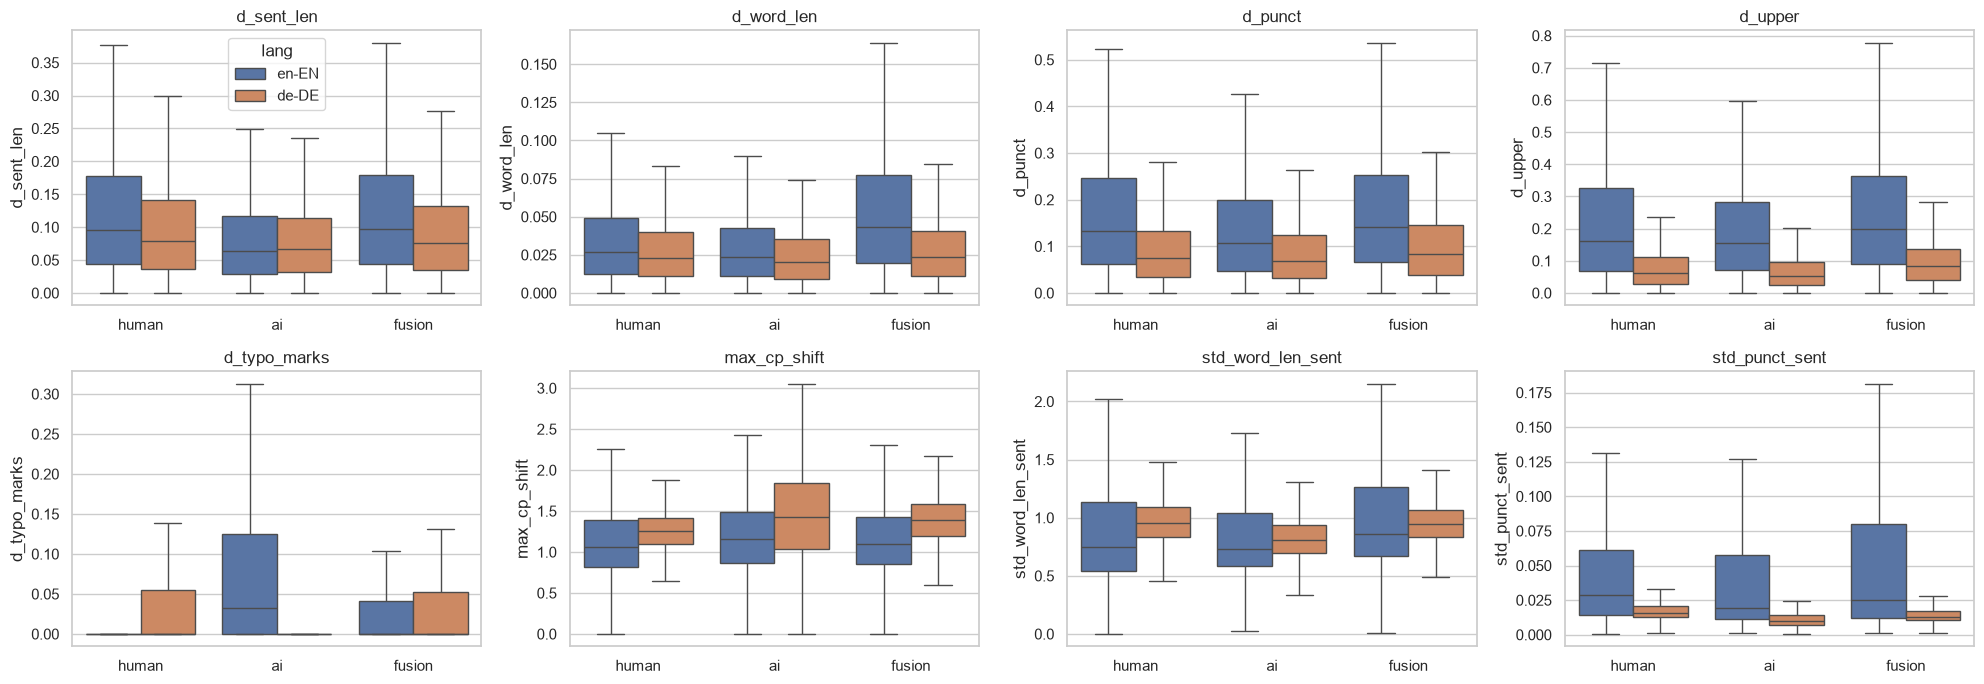

fusion-vs-rest AUC per language:


,en-EN,de-DE
d_sent_len,0.573,0.515
d_word_len,0.651,0.525
d_punct,0.553,0.540
d_upper,0.559,0.602
d_typo_marks,0.430,0.570
max_cp_shift,0.489,0.541
std_word_len_sent,0.585,0.605
std_punct_sent,0.526,0.555


In [14]:
def sent_feats(s):
    w = WORD_RE.findall(s)
    letters = [c for c in s if c.isalpha()]
    return (len(w),
            np.mean([len(x) for x in w]) if w else 0,
            sum(c in string.punctuation for c in s) / max(len(s), 1),
            sum(c.isupper() for c in letters) / max(len(letters), 1),
            int(any(c in s for c in "—“”’…„")))

SHIFT = ["d_sent_len", "d_word_len", "d_punct", "d_upper", "d_typo_marks", "max_cp_shift", "std_word_len_sent", "std_punct_sent"]

def shift_features(t):
    sents = split_sents(t)
    if len(sents) < 4:
        return dict.fromkeys(SHIFT, np.nan)
    M = np.array([sent_feats(s) for s in sents], dtype=float)
    h = len(M) // 2
    a, b = M[:h].mean(0), M[h:].mean(0)
    rel = np.abs(a - b) / (np.abs(a) + np.abs(b) + 1e-9)
    L = M[:, 0]   # change point in sentence length, normalised by its std
    cps = [abs(L[:k].mean() - L[k:].mean()) / (L.std() + 1e-9) for k in range(2, len(L) - 1)]
    return dict(zip(SHIFT, [rel[0], rel[1], rel[2], rel[3], abs(a[4] - b[4]),
                            max(cps) if cps else np.nan, M[:, 1].std(), M[:, 2].std()]))

sh = pd.DataFrame([shift_features(t) for t in train[TEXT]], index=train.index)
sh[[LABEL, LANG, DOMAIN]] = train[[LABEL, LANG, DOMAIN]]
print("texts with < 4 sentences (no shift features):")
display(sh[SHIFT[0]].isna().groupby([sh[LANG], sh[LABEL]]).mean().unstack().round(3))
display(sh.groupby([LANG, LABEL])[SHIFT].median().round(3))

fig, axes = plt.subplots(2, 4, figsize=(20, 7))
for i, (ax, f) in enumerate(zip(axes.flat, SHIFT)):
    sns.boxplot(data=sh, x=LABEL, y=f, hue=LANG, order=CLASSES, hue_order=LANGS, ax=ax, showfliers=False, legend=(i == 0))
    ax.set_title(f); ax.set_xlabel("")
plt.tight_layout(); plt.show()

ok = sh.dropna()
print("fusion-vs-rest AUC per language:")
display(pd.DataFrame({lang: auc_table(ok[ok[LANG] == lang], SHIFT)["fusion"] for lang in LANGS}).round(3))

## 9. Vocabulary: distinctive n-grams and stock AI phrases (per language)

In [15]:
from sklearn.feature_extraction.text import CountVectorizer

# class-balanced sample (up to BASELINE_N / 3 rows per label)
sample = train.sample(frac=1, random_state=RANDOM_STATE).groupby(LABEL).head(BASELINE_N // len(CLASSES))

for lang in LANGS:
    s = sample[sample[LANG] == lang]
    cv = CountVectorizer(ngram_range=(1, 2), min_df=5, max_features=50000, lowercase=True)
    X = cv.fit_transform(s[TEXT])
    vocab = np.array(cv.get_feature_names_out())
    tables = {}
    for cls in CLASSES:   # smoothed log-odds ratio: class vs rest
        m = (s[LABEL] == cls).values
        a = np.asarray(X[m].sum(0)).ravel() + 1
        b = np.asarray(X[~m].sum(0)).ravel() + 1
        tables[cls] = vocab[np.argsort(-(np.log(a / a.sum()) - np.log(b / b.sum())))[:25]]
    print(f"===== {lang}: most distinctive n-grams per label =====")
    display(pd.DataFrame(tables))

===== en-EN: most distinctive n-grams per label =====


,human,ai,fusion
0,if what,rise today,reconstructed missing
1,sincerely student_name,honourable member,missing part
2,sorry we,2000 word,missing section
3,ally mcbeal,case summary,middle section
4,mcbeal,15 2023,missing middle
5,hemp,2000 words,187 words
6,ivf,letter finds,part approx
7,put and,insert date,x1 xn
8,declares that,on insert,lm
9,johnston,2023,multipliers


===== de-DE: most distinctive n-grams per label =====


,human,ai,fusion
0,klimaforschung,heute stehe,fehlender teil
1,geldwäscherichtlinie,honorable,fehlenden abschnitt
2,und gerne,challenges,240 wörter
3,der oder,heute möchte,rede ca
4,vorhanden sein,honorable parlamentarierinnen,herausforderungen eingehen
5,ordentliches,abschließend appelliere,ca 240
6,mietspiegel,herren geschätzte,die östliche
7,90er jahren,sinne fordere,östliche partnerschaft
8,den 90er,anliegen heute,in xinjiang
9,es gehen,let,genau genommen


In [ ]:
AI_PHRASES = {
    "en-EN": ["delve", "moreover", "furthermore", "additionally", "crucial", "notably", "it is important to note",
              "in conclusion", "in summary", "overall", "ultimately", "tapestry", "landscape", "foster", "realm",
              "plays a crucial role", "a testament to", "navigating", "as an ai", "i hope this"],
    "de-DE": ["darüber hinaus", "zudem", "außerdem", "insgesamt", "zusammenfassend", "abschließend", "letztendlich",
              "es ist wichtig zu beachten", "von entscheidender bedeutung", "spielt eine entscheidende rolle",
              "nicht zuletzt", "vielfältig", "ein wichtiger aspekt", "im folgenden", "es lässt sich festhalten"],
}
for lang, phrases in AI_PHRASES.items():
    d = train[train[LANG] == lang]
    low = d[TEXT].str.lower()
    rates = pd.DataFrame({p: low.str.contains(re.escape(p)).groupby(d[LABEL]).mean() * 100 for p in phrases}).T
    rates = rates.reindex(columns=CLASSES)
    print(f"===== {lang}: % of texts containing phrase =====")
    display(rates[(rates > 0).any(axis=1)].style.background_gradient(axis=1, cmap="Reds").format("{:.2f}%"))

# First two words per label — templates / prompts often leak here
first = train[TEXT].str.strip().str.split().str[:2].str.join(" ").str.lower()
for lang in LANGS:
    m = train[LANG] == lang
    print(f"===== {lang}: most common openings =====")
    display(pd.DataFrame({cls: pd.Series([f"{w} ×{n}" for w, n in first[m & (train[LABEL] == cls)].value_counts().head(10).items()], dtype=object)
                          for cls in CLASSES}))

===== en-EN: % of texts containing phrase =====


label,human,ai,fusion
delve,0.09%,6.73%,1.87%
moreover,2.50%,10.10%,12.07%
furthermore,3.11%,16.88%,18.08%
additionally,0.88%,5.28%,6.78%
crucial,1.97%,25.60%,14.37%
notably,0.48%,1.93%,1.10%
it is important to note,0.04%,0.27%,0.24%
in conclusion,4.89%,13.91%,3.48%
in summary,0.17%,0.48%,0.65%
overall,3.86%,6.51%,6.65%


===== de-DE: % of texts containing phrase =====


label,human,ai,fusion
darüber hinaus,5.20%,17.78%,16.90%
zudem,4.46%,3.46%,7.10%
außerdem,5.67%,0.52%,4.74%
insgesamt,11.47%,1.48%,10.40%
zusammenfassend,0.52%,1.91%,1.65%
abschließend,3.98%,9.94%,3.99%
letztendlich,2.95%,3.72%,4.47%
es ist wichtig zu beachten,0.00%,0.02%,0.01%
von entscheidender bedeutung,0.13%,10.69%,4.42%
spielt eine entscheidende rolle,0.02%,0.63%,0.18%
